# From the K3 graph to Quantum Circuits

This walkthrough turns a triangle graph into a resource table for **Logique
and four Saha–Belletti methods**. K3 has only six input bits, so we can check
all inputs and inspect the circuits as we go.

Read the notebook in this order:

1. Read the graph and build its Boolean predicate.
2. Compile and verify the Logique circuit.
3. Build one Grover iteration and the four baseline circuits.
4. Count resources and compare them with the archived paper row.

Each section introduces the library functions it uses. The notebook defines
its benchmark choices directly and uses ordinary imports from `logique`.

We preserve the paper's historical choices: remove precolors, accept unused
binary color codes in the predicate, and use a diffusion reflection different
from the initial preparation. Each choice is explained at the relevant step.

## 1. Set up the notebook

Use the environment from the [setup guide](../../docs/setup.md), including the
comparison and notebook extras, native bridge, system Graphviz, and manuscript
Qiskit MCX-depth patch (`tools/patch_qiskit_depth.py`). If you edit library code,
restart the kernel before running again.

Imports appear just before the code that first needs them. Run the cells in
order; later sections reuse names introduced earlier.

### Choose the input and output folders

Run from the repository root, or set `LOGIQUE_WORKSPACE` to the checkout path.
The notebook runner supplies `LOGIQUE_OUTPUT`; an interactive run creates a
new folder under `dump/`.

In [150]:
from pathlib import Path
import os

from logique.paths import new_dump_directory

ROOT = Path(os.environ.get("LOGIQUE_WORKSPACE", Path.cwd())).resolve()
BENCHMARK = "K3"
input_path = ROOT / "datasets/graphs/benchmarks" / f"{BENCHMARK}.col"
assert input_path.is_file(), "Run from the repository root or set LOGIQUE_WORKSPACE."

if "LOGIQUE_OUTPUT" in os.environ:
    OUT = Path(os.environ["LOGIQUE_OUTPUT"]).resolve()
else:
    OUT = new_dump_directory("illustrative_example_v2", root=ROOT / "dump")
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

print("Artifacts:", OUT)

Artifacts: /Users/mac/PhD/logique/dump/1018223814-illustrative-example-v2


## 2. Read the graph

The input file fixes vertex 1 to color 0 (`n 1 0`). Remove that precolor with
`replace(original, precolored={})` to reproduce the paper's problem.

In [151]:
from dataclasses import replace

from logique.coloring import read_dimacs
from logique.coloring.model import ColoringProblem

print(input_path.read_text())
original : ColoringProblem = read_dimacs(input_path)
problem : ColoringProblem = replace(original, precolored={})
print("Removed precolors:", dict(original.precolored))
print(
    "Replay vertices, edges, colors:", problem.vertices, problem.edges, problem.colors
)

c FILE: K3.col
c K3 is the simplest non-trivial example for vertex coloring problems 
c since it requires the minimum number of colors (3) where each vertex 
c must have a unique color.
c 3 vertices, 3 edges, 3 colors
p edge 3 3
n 1 0
e 1 2
e 1 3
e 2 3
x colors 3
Removed precolors: {1: 0}
Replay vertices, edges, colors: (1, 2, 3) ((1, 2), (1, 3), (2, 3)) 3


The first drawing shows the precolor in the input file. The second shows the
unconstrained triangle used for the paper benchmark. Both keep the original
one-based vertex labels.

### Display and save the graph drawings

Use this small helper for the drawings below and later figures. It saves each
figure as PNG and SVG, then shows it inline.

In [152]:
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def show_figure(figure, stem: str) -> None:
    """Display a figure and save PNG and SVG copies in this run."""
    figure.savefig(FIGURES / f"{stem}.svg", bbox_inches="tight")
    figure.savefig(FIGURES / f"{stem}.png", dpi=140, bbox_inches="tight")
    display(Image(filename=str(FIGURES / f"{stem}.png")))
    plt.close(figure)

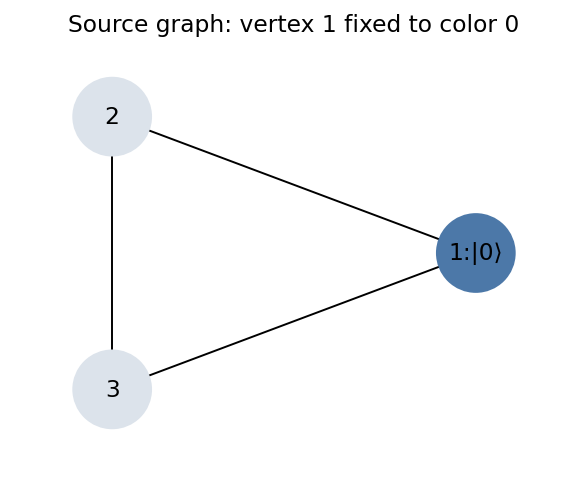

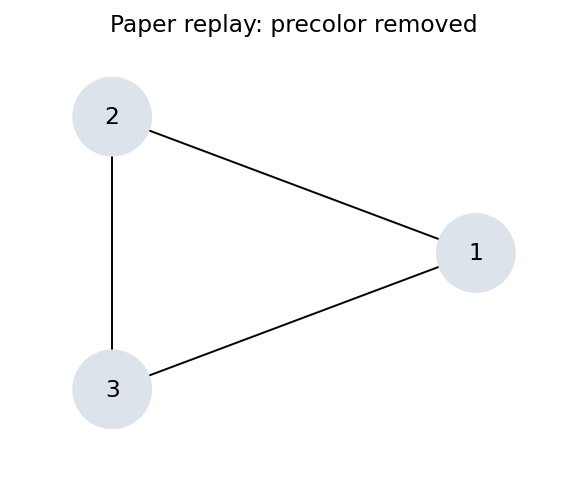

In [153]:
import networkx as nx

from logique.visualization.graphs import draw_colored_graph

palette = ("#4c78a8", "#f58518", "#54a24b")
for title, instance, stem in (
    ("Source graph: vertex 1 fixed to color 0", original, "source-graph"),
    ("Paper replay: precolor removed", problem, "paper-graph"),
):
    graph : nx.Graph = instance.to_networkx()
    for vertex in graph:
        color = instance.precolored.get(vertex)
        graph.nodes[vertex]["color"] = "#dce3eb" if color is None else palette[color]
        graph.nodes[vertex]["color_idx"] = -1 if color is None else color
    draw_colored_graph(
        graph,
        name=str(FIGURES / f"{stem}.png"),
        pos=nx.circular_layout(graph),
        figsize=(4, 3),
        node_size=1600,
    )
    figure = plt.gcf()
    figure.axes[0].set_title(title)
    figure.axes[0].margins(0.20)
    show_figure(figure, stem)

## 3. Turn each edge into a Boolean inequality

Two bits encode each vertex color, least-significant bit first:
$00\mapsto0$, $01\mapsto1$, $10\mapsto2$, $11\mapsto3$.
Color 3 is an unused code for this three-color problem.

For an edge $(u,v)$, the predicate is
$(v_{u,0}\oplus v_{v,0})\lor(v_{u,1}\oplus v_{v,1})$.
AND the three edge predicates to require that adjacent colors differ.
`edge_coloring_expression()` preserves the expression and variable ordering
used by the original generator. It adds neither precolors nor color-range
constraints.

We use a four-color `reference_encoding` only to decode all six-bit inputs and
provide an independent edge-only verifier. This does **not** change the
three-color initial preparation used later.

In [154]:
from logique.coloring import edge_coloring_expression, encode_coloring

expression, variables = edge_coloring_expression(problem)
bits_per_color = (problem.colors - 1).bit_length()
reference_encoding = encode_coloring(replace(problem, colors=1 << bits_per_color))
input_count = reference_encoding.input_count

print(expression)
assert input_count == 6

((v1_0 ^ v2_0) | (v1_1 ^ v2_1)) & ((v1_0 ^ v3_0) | (v1_1 ^ v3_1)) & ((v2_0 ^ v3_0) | (v2_1 ^ v3_1))


### Map color bits to inputs

Each vertex has two input bits. This table connects expression variables,
qubit indices, and the vertex/bit labels used in the diagrams.

In [155]:
import pandas as pd

input_labels = [None] * input_count
for vertex, wires in reference_encoding.input_mapping.items():
    for bit, wire in enumerate(wires):
        input_labels[wire] = f"x_{vertex},{bit}"
assert all(label is not None for label in input_labels)
mapping = pd.DataFrame(
    [
        {
            "vertex": vertex,
            "color bit": bit,
            "input qubit": wire,
            "expression variable": variables[wire],
            "diagram label": input_labels[wire],
        }
        for vertex, wires in reference_encoding.input_mapping.items()
        for bit, wire in enumerate(wires)
    ]
)
display(mapping)

,vertex,color bit,input qubit,expression variable,diagram label
0,1,0,0,v1_0,"x_1,0"
1,1,1,1,v1_1,"x_1,1"
2,2,0,2,v2_0,"x_2,0"
3,2,1,3,v2_1,"x_2,1"
4,3,0,4,v3_0,"x_3,0"
5,3,1,5,v3_1,"x_3,1"


### Check what the predicate accepts

Evaluate all 64 inputs using the independent classical graph checker. The
edge-only predicate accepts 24 bitstrings. Restricting to three colors leaves
six; keeping the original precolor leaves two.

In [156]:
import numpy as np

assignments = [reference_encoding.decode(basis) for basis in range(1 << input_count)]
edge_valid = np.array([reference_encoding.problem.is_valid(a) for a in assignments])
three_color_valid = np.array([problem.is_valid(a) for a in assignments])
original_valid = np.array([original.is_valid(a) for a in assignments])
uses_unused_code = np.array(
    [any(c >= problem.colors for c in a.values()) for a in assignments]
)

In [157]:
display(
    pd.DataFrame(
        {
            "predicate": [
                "Paper edge-only",
                "Three colors, no precolor",
                "Original file with precolor",
            ],
            "accepted bitstrings out of 64": [
                int(edge_valid.sum()),
                int(three_color_valid.sum()),
                int(original_valid.sum()),
            ],
        }
    )
)

assert (
    int(edge_valid.sum()),
    int(three_color_valid.sum()),
    int(original_valid.sum()),
) == (24, 6, 2)

,predicate,accepted bitstrings out of 64
0,Paper edge-only,24
1,"Three colors, no precolor",6
2,Original file with precolor,2


For a concrete comparison, inspect one proper three-coloring and one input
that the edge-only predicate accepts using the unused color code 3.

In [158]:
examples = [
    int(np.flatnonzero(three_color_valid)[0]),
    int(np.flatnonzero(edge_valid & uses_unused_code)[0]),
]
display(
    pd.DataFrame(
        [
            {
                "basis": basis,
                "q5...q0": f"{basis:06b}",
                "vertex colors": assignments[basis],
                "edge-only accepts": bool(edge_valid[basis]),
                "three-color accepts": bool(three_color_valid[basis]),
            }
            for basis in examples
        ]
    )
)

,basis,q5...q0,vertex colors,edge-only accepts,three-color accepts
0,6,000110,"{1: 2, 2: 1, 3: 0}",True,True
1,7,000111,"{1: 3, 2: 1, 3: 0}",True,False


## 4. Compile the predicate

`synthesize_expression()` builds an XAG (a network of XOR and AND gates) and
turns it into a quantum circuit. It also exports Boolean networks for checking
and drawing the predicate.

In [159]:
from logique.paths import native_executable
from logique.synthesis import synthesize_expression

EXECUTABLE = native_executable(
    os.environ.get("LOGIQUE_NATIVE_EXECUTABLE")
    or ROOT / "external/native/boolean_synthesis/build/boolean_synthesis"
)
print("Native bridge:", EXECUTABLE)

synthesis = synthesize_expression(expression, variables, executable=EXECUTABLE)
# synthesis = synthesize_expression(expression, variables)

Native bridge: /Users/mac/PhD/logique/external/native/boolean_synthesis/build/boolean_synthesis


### Inspect the Boolean logic

The native source and mapped networks represent the same function, but may
have different gate structures. They are reference views rather than a trace
of every quantum instruction. First inspect their sizes and generated Verilog.

In [160]:
from logique.visualization.boolean import graph_stats

source_network = synthesis.metadata["source_network"]
reference_network = synthesis.metadata["network"]
(OUT / "K3_expression.v").write_text(synthesis.metadata["source_verilog"])
print(synthesis.metadata["source_verilog"])

display(
    pd.DataFrame(
        [
            {"representation": label, **graph_stats(network)}
            for label, network in (
                ("Native source reference", source_network),
                ("Native mapped reference", reference_network),
            )
        ]
    )
)

module top( x0 , x1 , x2 , x3 , x4 , x5 , y0 );
  input x0 , x1 , x2 , x3 , x4 , x5 ;
  output y0 ;
  wire n7 , n8 , n9 , n10 , n11 , n12 , n13 , n14 , n15 , n16 , n17 ;
  assign n7 = x2 ^ x0 ;
  assign n8 = x3 ^ x1 ;
  assign n9 = ~n7 & ~n8 ;
  assign n10 = x4 ^ x0 ;
  assign n11 = x5 ^ x1 ;
  assign n12 = ~n10 & ~n11 ;
  assign n13 = ~n9 & ~n12 ;
  assign n14 = x4 ^ x2 ;
  assign n15 = x5 ^ x3 ;
  assign n16 = ~n14 & ~n15 ;
  assign n17 = n13 & ~n16 ;
  assign y0 = n17 ;
endmodule



,representation,AND,XOR,LUT,levels,used_inputs,shared_internal_nodes
0,Native source reference,5,6,0,4,6,0
1,Native mapped reference,5,6,0,4,6,0


Check both reference networks against the edge predicate on all 64 inputs.

In [161]:
from logique.verification.classical import input_assignments, truth_outputs
from logique.visualization.boolean import evaluate_gate_rows

input_bits = input_assignments(input_count)
np.testing.assert_array_equal(truth_outputs(source_network, input_bits)[0], edge_valid)
np.testing.assert_array_equal(
    evaluate_gate_rows(reference_network, input_bits, input_labels=input_labels)[0],
    edge_valid,
)

Read the mapped network as factored equations. Here $x_{v,b}$ is bit $b$ of
vertex $v$, using the labels from the input table.

In [162]:
from IPython.display import Math

from logique.visualization.boolean import latex_blocks

for block in latex_blocks(
    reference_network, rows_per_block=6, input_labels=input_labels
):
    display(Math(block))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The next cell draws both networks and a digital-gate schematic. Complemented
edges are inversions; crossings connect only where a dot is drawn. A separate
expression-XAG drawing is available in the final inspection section.

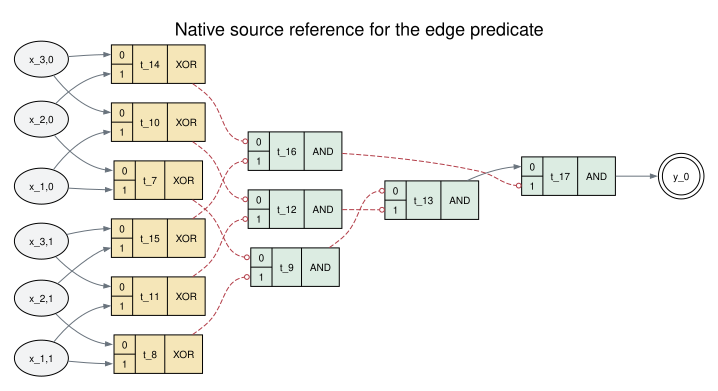

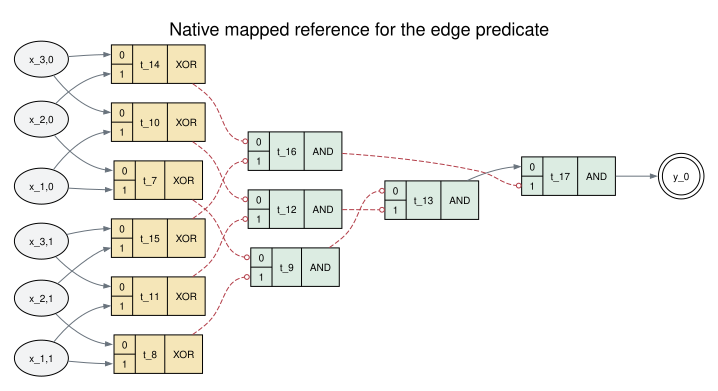

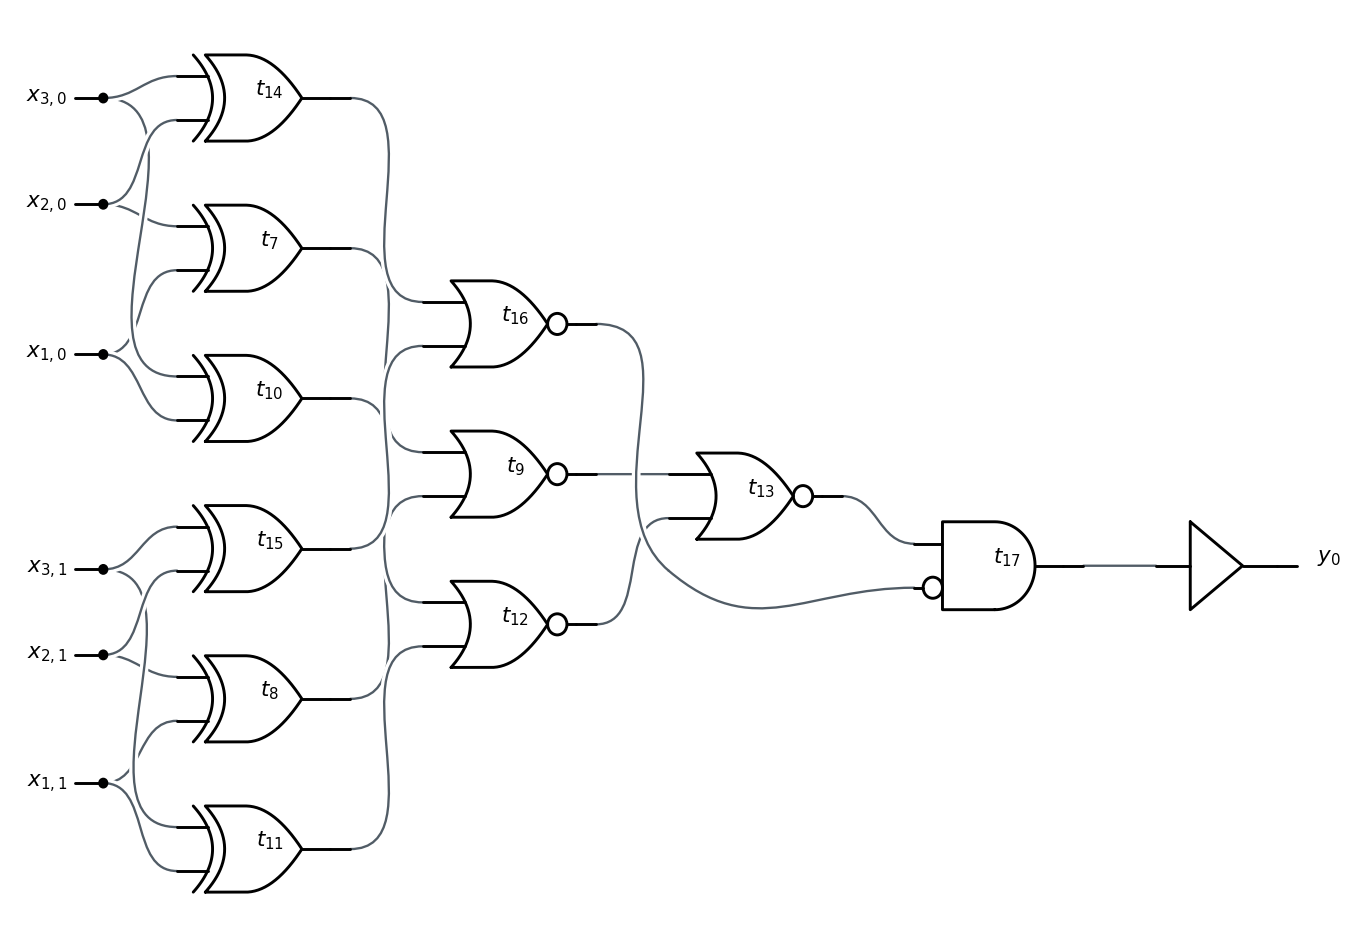

In [163]:
from IPython.display import SVG

from logique.visualization.boolean import graphviz_graph, schematic_figure

for label, network, stem in (
    (
        "Native source reference for the edge predicate",
        source_network,
        "source-reference-network",
    ),
    (
        "Native mapped reference for the edge predicate",
        reference_network,
        "mapped-reference-network",
    ),
):
    dot = graphviz_graph(network, label, input_labels=input_labels)
    (FIGURES / f"{stem}.dot").write_text(dot.source)
    svg = dot.pipe(format="svg")
    (FIGURES / f"{stem}.svg").write_bytes(svg)
    display(SVG(data=svg))

show_figure(
    schematic_figure(reference_network, input_labels=input_labels),
    "edge-predicate-schematic",
)

## 5. Inspect and verify the actual quantum computation

The raw circuit has data inputs, one output target, and workspace. Keep the
phases of controlled $R_x(\pm\pi)$ gates: they cannot be replaced by Toffolis
just because their computational-basis actions look similar.

`circuit_window()` shows a labeled excerpt, followed by the complete raw
circuit. An excerpt is a reading aid, not an executable sub-oracle.

In [164]:
inputs = synthesis.metadata["input_qubits"]
outputs = synthesis.metadata["output_qubits"]
workspace = sorted(
    set(range(synthesis.circuit.num_qubits)) - set(inputs) - set(outputs)
)
display(
    pd.DataFrame(
        [
            {"role": "Data", "qubits": inputs},
            {"role": "Output target", "qubits": outputs},
            {"role": "Workspace", "qubits": workspace},
        ]
    )
)
print("Raw allocated qubits:", synthesis.circuit.num_qubits)
print("Raw instructions:", len(synthesis.circuit))
display(
    pd.Series(dict(synthesis.circuit.count_ops()), name="operation count").to_frame()
)

,role,qubits
0,Data,"[0, 1, 2, 3, 4, 5]"
1,Output target,[6]
2,Workspace,"[7, 8, 9, 10]"


Raw allocated qubits: 11
Raw instructions: 33


,operation count
cx,24
ccrx_o0,8
ccx_o1,1


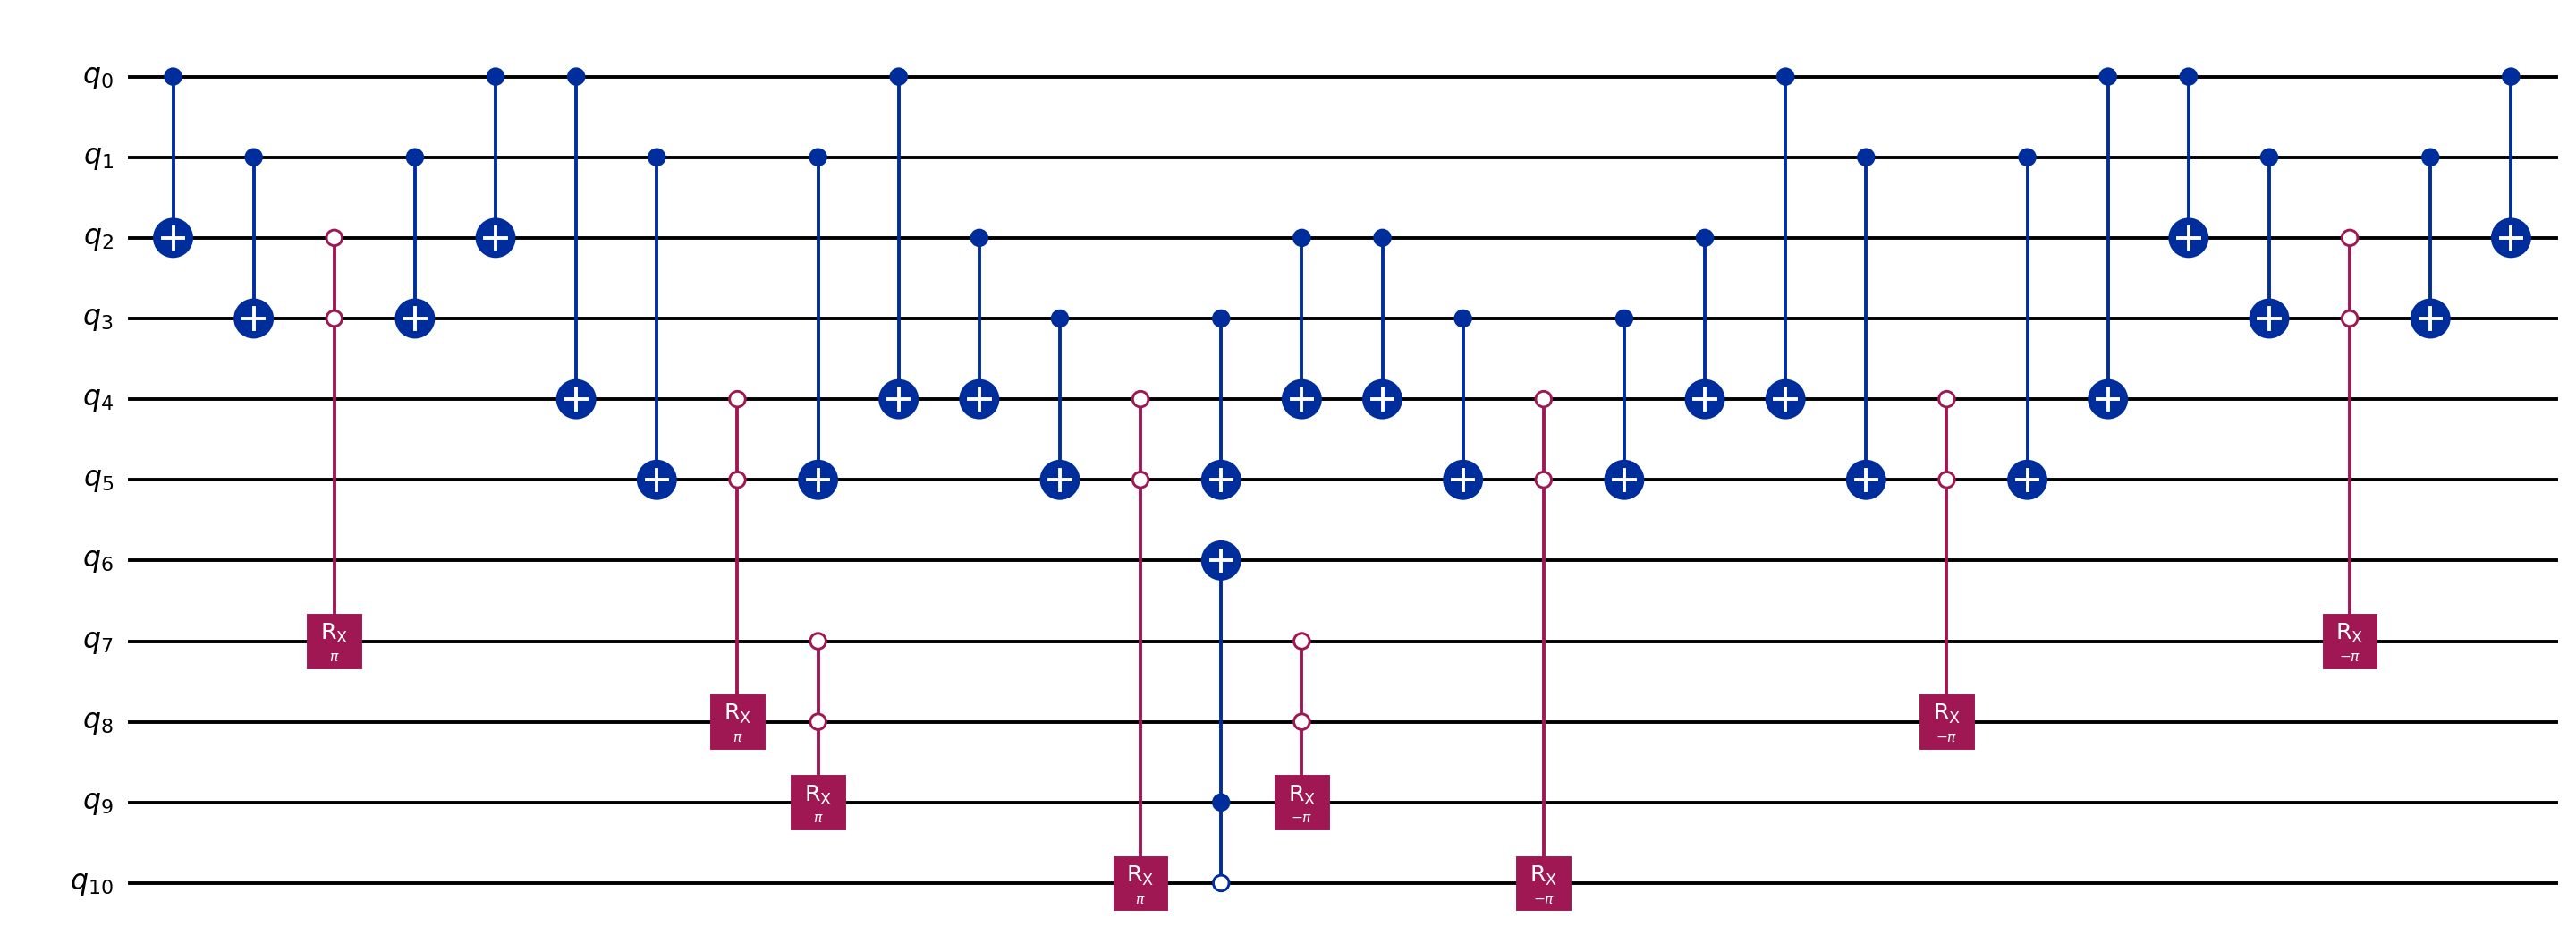

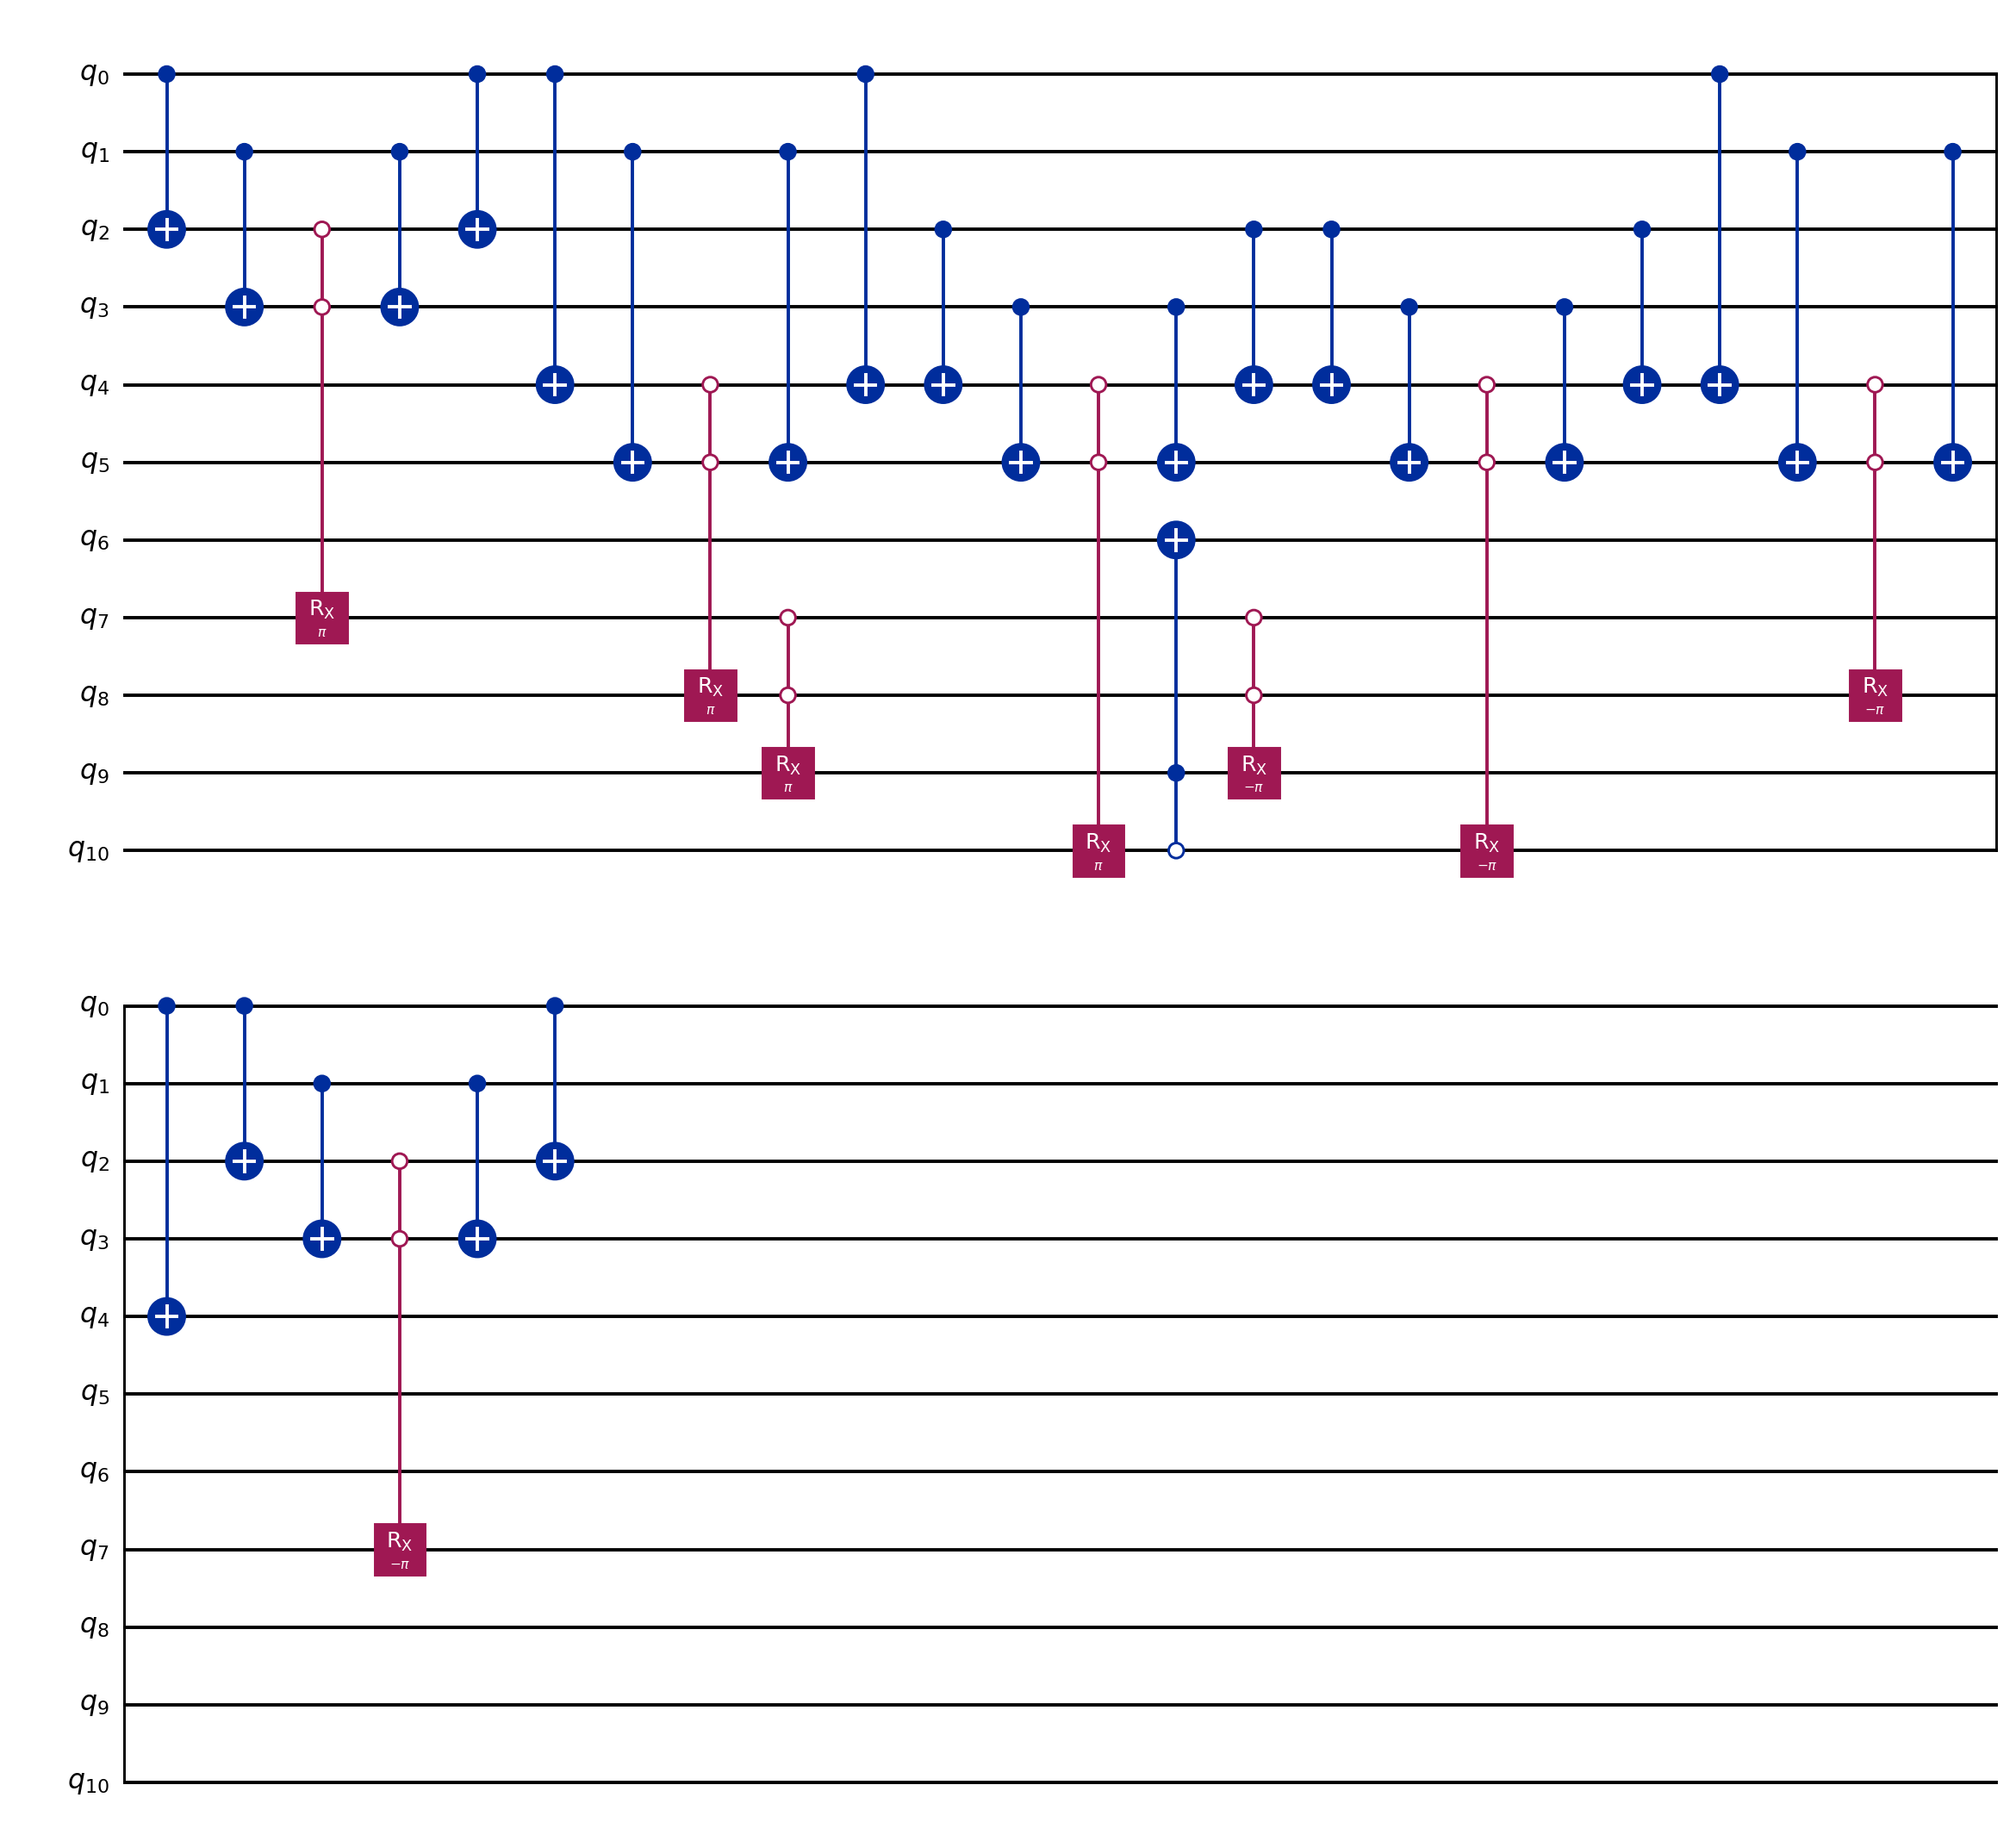

In [165]:
from logique.visualization.circuits import circuit_window

show_figure(circuit_window(synthesis, start=0, count=40), "raw-circuit-excerpt")
show_figure(
    synthesis.circuit.draw("mpl", fold=24, idle_wires=False), "raw-circuit-full"
)

### Why check both target values?

Before phase kickback, require the raw computation to implement
$|x\rangle|y\rangle|0\rangle\mapsto
|x\rangle|y\oplus f(x)\rangle|0\rangle$ for **both** $y=0$ and $y=1$,
with no extra input-dependent phase. By linearity, starting the target in
$|-\rangle$ then applies $(-1)^{f(x)}$ and restores the workspace.

`verify_kickback_oracle()` checks all 64 inputs, both target bits, phase,
input preservation, and workspace restoration against the independent graph
predicate. This establishes the Logique oracle contract; it does not verify
the historical baseline circuits.

In [166]:
import json

from logique.verification import verify_kickback_oracle

verification = verify_kickback_oracle(
    synthesis, encoding=reference_encoding, sampled=False, seed=7
)
display(pd.Series(verification, name="verification").to_frame())
assert verification["status"] == "exhaustive"
assert verification["assignments"] == 64
assert verification["marked_assignments"] == 24
assert verification["target_initializations"] == [0, 1]
assert all(
    verification[key]
    for key in ("phase_exact", "inputs_restored", "workspace_restored")
)
(OUT / "kickback_verification.json").write_text(
    json.dumps(verification, indent=2) + "\n"
)

,verification
status,exhaustive
assignments,64
target_initializations,"[0, 1]"
marked_assignments,24
seed,None
reference,edge-only coloring predicate over all encoded ...
phase_exact,True
inputs_restored,True
workspace_restored,True


293

## 6. Prepare three colors, then apply historical diffusion

Each vertex starts in
$|s_3\rangle=(|00\rangle+|01\rangle+|10\rangle)/\sqrt3$,
so the data register initially contains 27 equally likely assignments, with
no unused code 3. Use the same `UniformSuperpositionGate(3)` decomposition as
the paper: substituting another equivalent preparation could change costs.

For replay, diffusion reflects about $|s_{64}\rangle=H^{\otimes6}|0\rangle$,
not about $|s_3\rangle^{\otimes3}$. The historical helper implements
$I-2|s_{64}\rangle\langle s_{64}|$. Its reflection can introduce amplitude
on unused codes. The two preparations below make that distinction visible.

In [167]:
from qiskit import QuantumCircuit
from qiskit.circuit.library.data_preparation.state_preparation import (
    UniformSuperpositionGate,
)

vertex_preparation = QuantumCircuit(bits_per_color)
vertex_preparation.append(
    UniformSuperpositionGate(problem.colors), range(bits_per_color)
)
vertex_preparation = vertex_preparation.decompose()
preparation = QuantumCircuit(input_count)
for start in range(0, input_count, bits_per_color):
    preparation.compose(
        vertex_preparation, range(start, start + bits_per_color), inplace=True
    )

The initial state uses only valid colors. Historical diffusion instead uses
Hadamards on every data qubit; draw both preparations to see the difference.

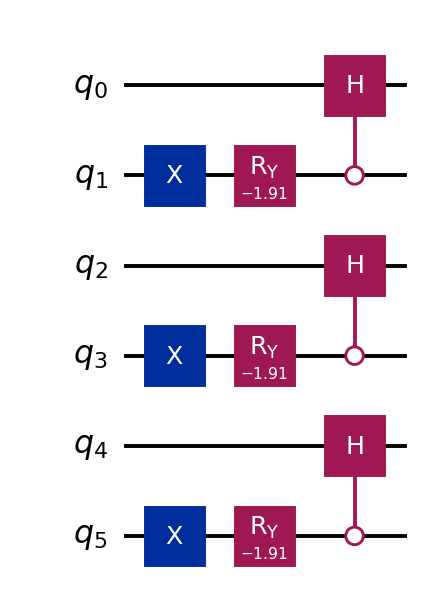

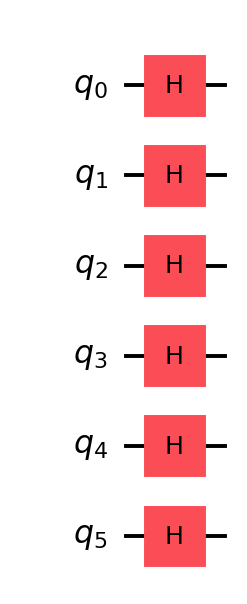

In [168]:
reflection_preparation = QuantumCircuit(input_count)
reflection_preparation.h(range(input_count))
show_figure(preparation.draw("mpl", fold=24), "valid-color-preparation")
show_figure(reflection_preparation.draw("mpl", fold=24), "reflection-preparation")

Now combine the verified oracle and the two preparations into one Grover
iteration. `vcgc` is the historical name used for Logique in the paper tables.

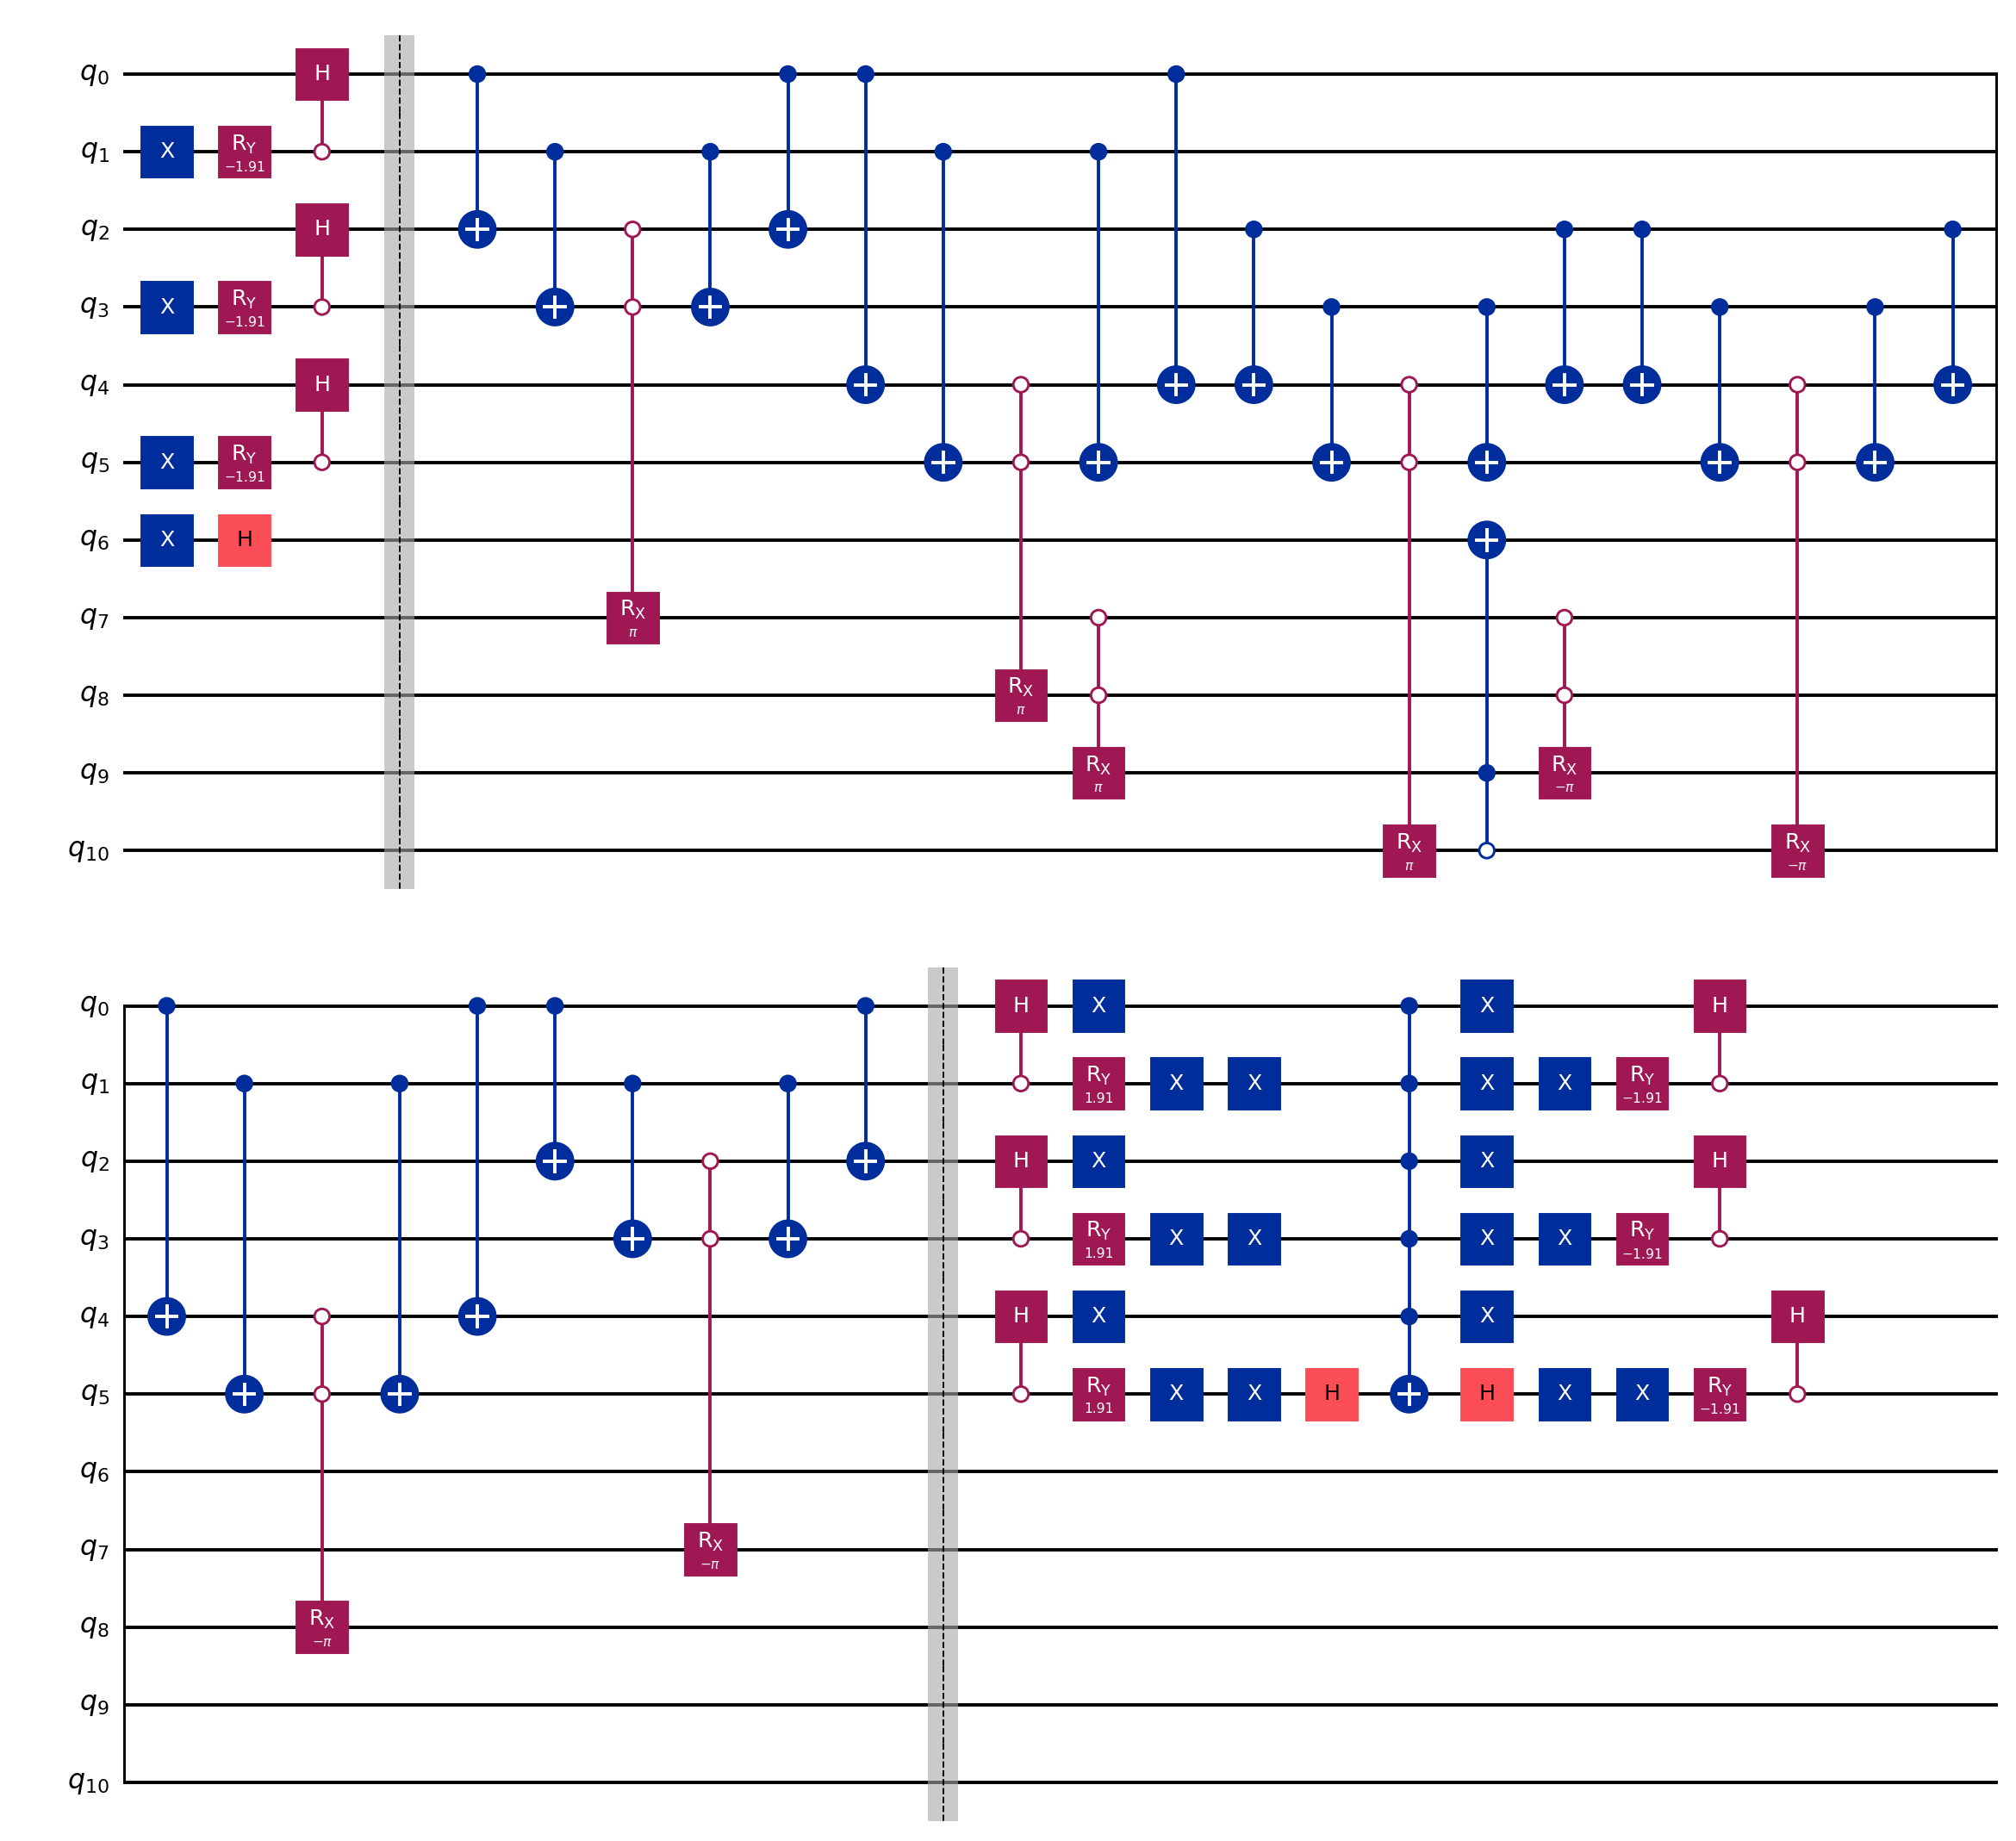

In [169]:
from logique.circuits.grover import kickback_grover_circuit

vcgc = kickback_grover_circuit(
    synthesis,
    preparation=preparation,
    # reflection_preparation=reflection_preparation,
    iterations=1,
)
show_figure(vcgc.draw("mpl", fold=24, idle_wires=False), "one-grover-iteration")

The full circuit initializes the output in $|-\rangle$, applies the raw XAG
once, then diffuses the data. No extra inverse of the XAG is added: its clean
XOR action was checked above.

For this 11-qubit example we can simulate the complete state locally and
sum probabilities over the output and workspace. The groups below separate
proper three-colorings, color conflicts using only valid codes, and all
assignments containing the unused code. This is an exact noiseless illustration
of one historical iteration, not an optimized iteration count.

In [170]:
from qiskit.quantum_info import Statevector

assert vcgc.num_qubits <= 16, "Keep dense statevector demonstrations small."
before = Statevector.from_instruction(preparation).probabilities()
final_state = Statevector.from_instruction(vcgc)
after = final_state.probabilities(inputs)
np.testing.assert_allclose(before.sum(), 1, atol=1e-9)
np.testing.assert_allclose(after.sum(), 1, atol=1e-9)
np.testing.assert_allclose(before[uses_unused_code], 0, atol=1e-9)
np.testing.assert_allclose(final_state.probabilities(workspace)[0], 1, atol=1e-9)
assert after[uses_unused_code].sum() > 0

In [171]:
groups = {
    "Proper three-coloring": three_color_valid,
    "Valid codes, edge conflict": ~uses_unused_code & ~three_color_valid,
    "Contains unused code 3": uses_unused_code,
}
probabilities = pd.DataFrame(
    [
        {
            "assignment group": label,
            "bitstrings": int(mask.sum()),
            "Initial": float(before[mask].sum()),
            "After one iteration": float(after[mask].sum()),
        }
        for label, mask in groups.items()
    ]
).set_index("assignment group")
display(probabilities)
probabilities.to_csv(OUT / "probability_groups.csv")

,bitstrings,Initial,After one iteration
assignment group,,,
Proper three-coloring,6,0.222222,9.903978e-01
"Valid codes, edge conflict",21,0.777778,9.602195e-03
Contains unused code 3,37,0.000000,2.018053e-31


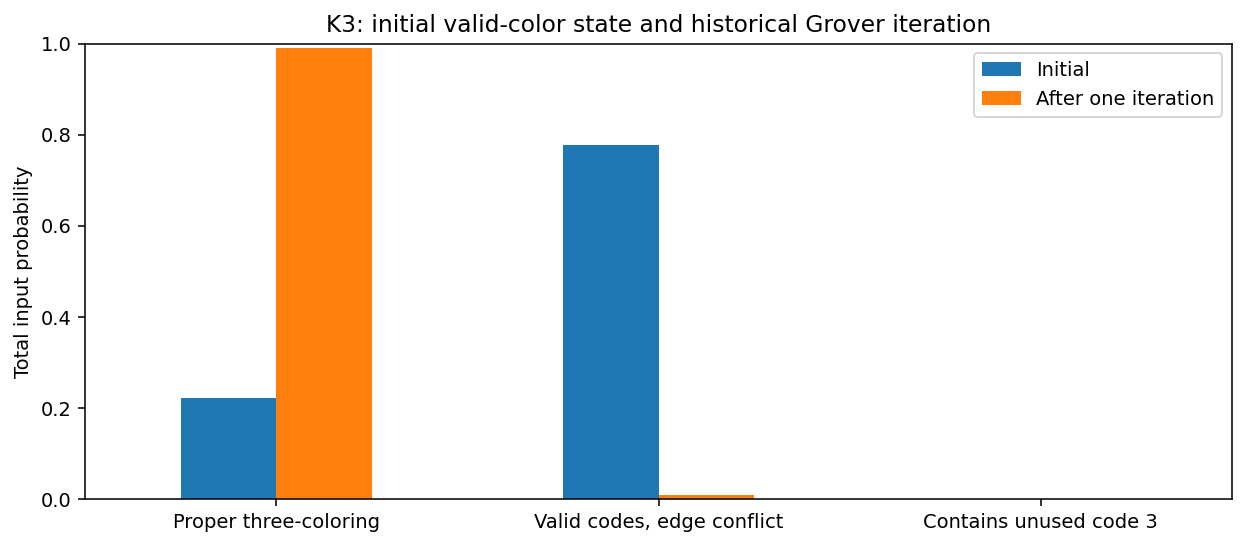

In [172]:
figure, ax = plt.subplots(figsize=(9, 4))
probabilities[["Initial", "After one iteration"]].plot.bar(ax=ax, rot=0)
ax.set_ylabel("Total input probability")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.set_title("K3: initial valid-color state and historical Grover iteration")
figure.tight_layout()
show_figure(figure, "probability-groups")

## 7. Construct the other four methods

Use `original`, `minimal`, `simple`, and `balanced` variants
of the Saha–Belletti dependency, each with one Grover iteration and a
Hadamard-prepared data register. Its adapter preserves one-based graph labels
with `preserve_labels=True`, including their mismatch with the dependency's
indexing, and retains final measurements with `measure=True`.

These settings reproduce historical circuits and costs. The comparison does
not establish equivalent preparations or correctness of those baseline
circuits. We retain the baseline circuits for export, show one representative
diagram here, and save all four diagrams for inspection.

In [92]:
from logique.synthesis.saha_belletti import comparison_circuit

variants = ("original", "minimal", "simple", "balanced")
circuits = {"vcgc": vcgc}
for variant in variants:
    circuits[f"sb_{variant}"] = comparison_circuit(
        problem, variant, iterations=1, preserve_labels=True, measure=True
    )
methods = list(circuits)

Grover iterations: 1
Grover iterations: 1
Grover iterations: 1
Grover iterations: 1


In [93]:
display(
    pd.DataFrame(
        [
            {
                "method": method,
                "allocated qubits": circuit.num_qubits,
                "classical bits": circuit.num_clbits,
                "measurements": int(circuit.count_ops().get("measure", 0)),
            }
            for method, circuit in circuits.items()
        ]
    )
)
assert len(circuits) == 5

,method,allocated qubits,classical bits,measurements
0,vcgc,11,0,0
1,sb_original,11,6,6
2,sb_minimal,11,6,6
3,sb_simple,13,6,6
4,sb_balanced,11,6,6


Inspect the original baseline below. Save the other three diagrams as SVGs so
the walkthrough does not display four large circuits in a row.

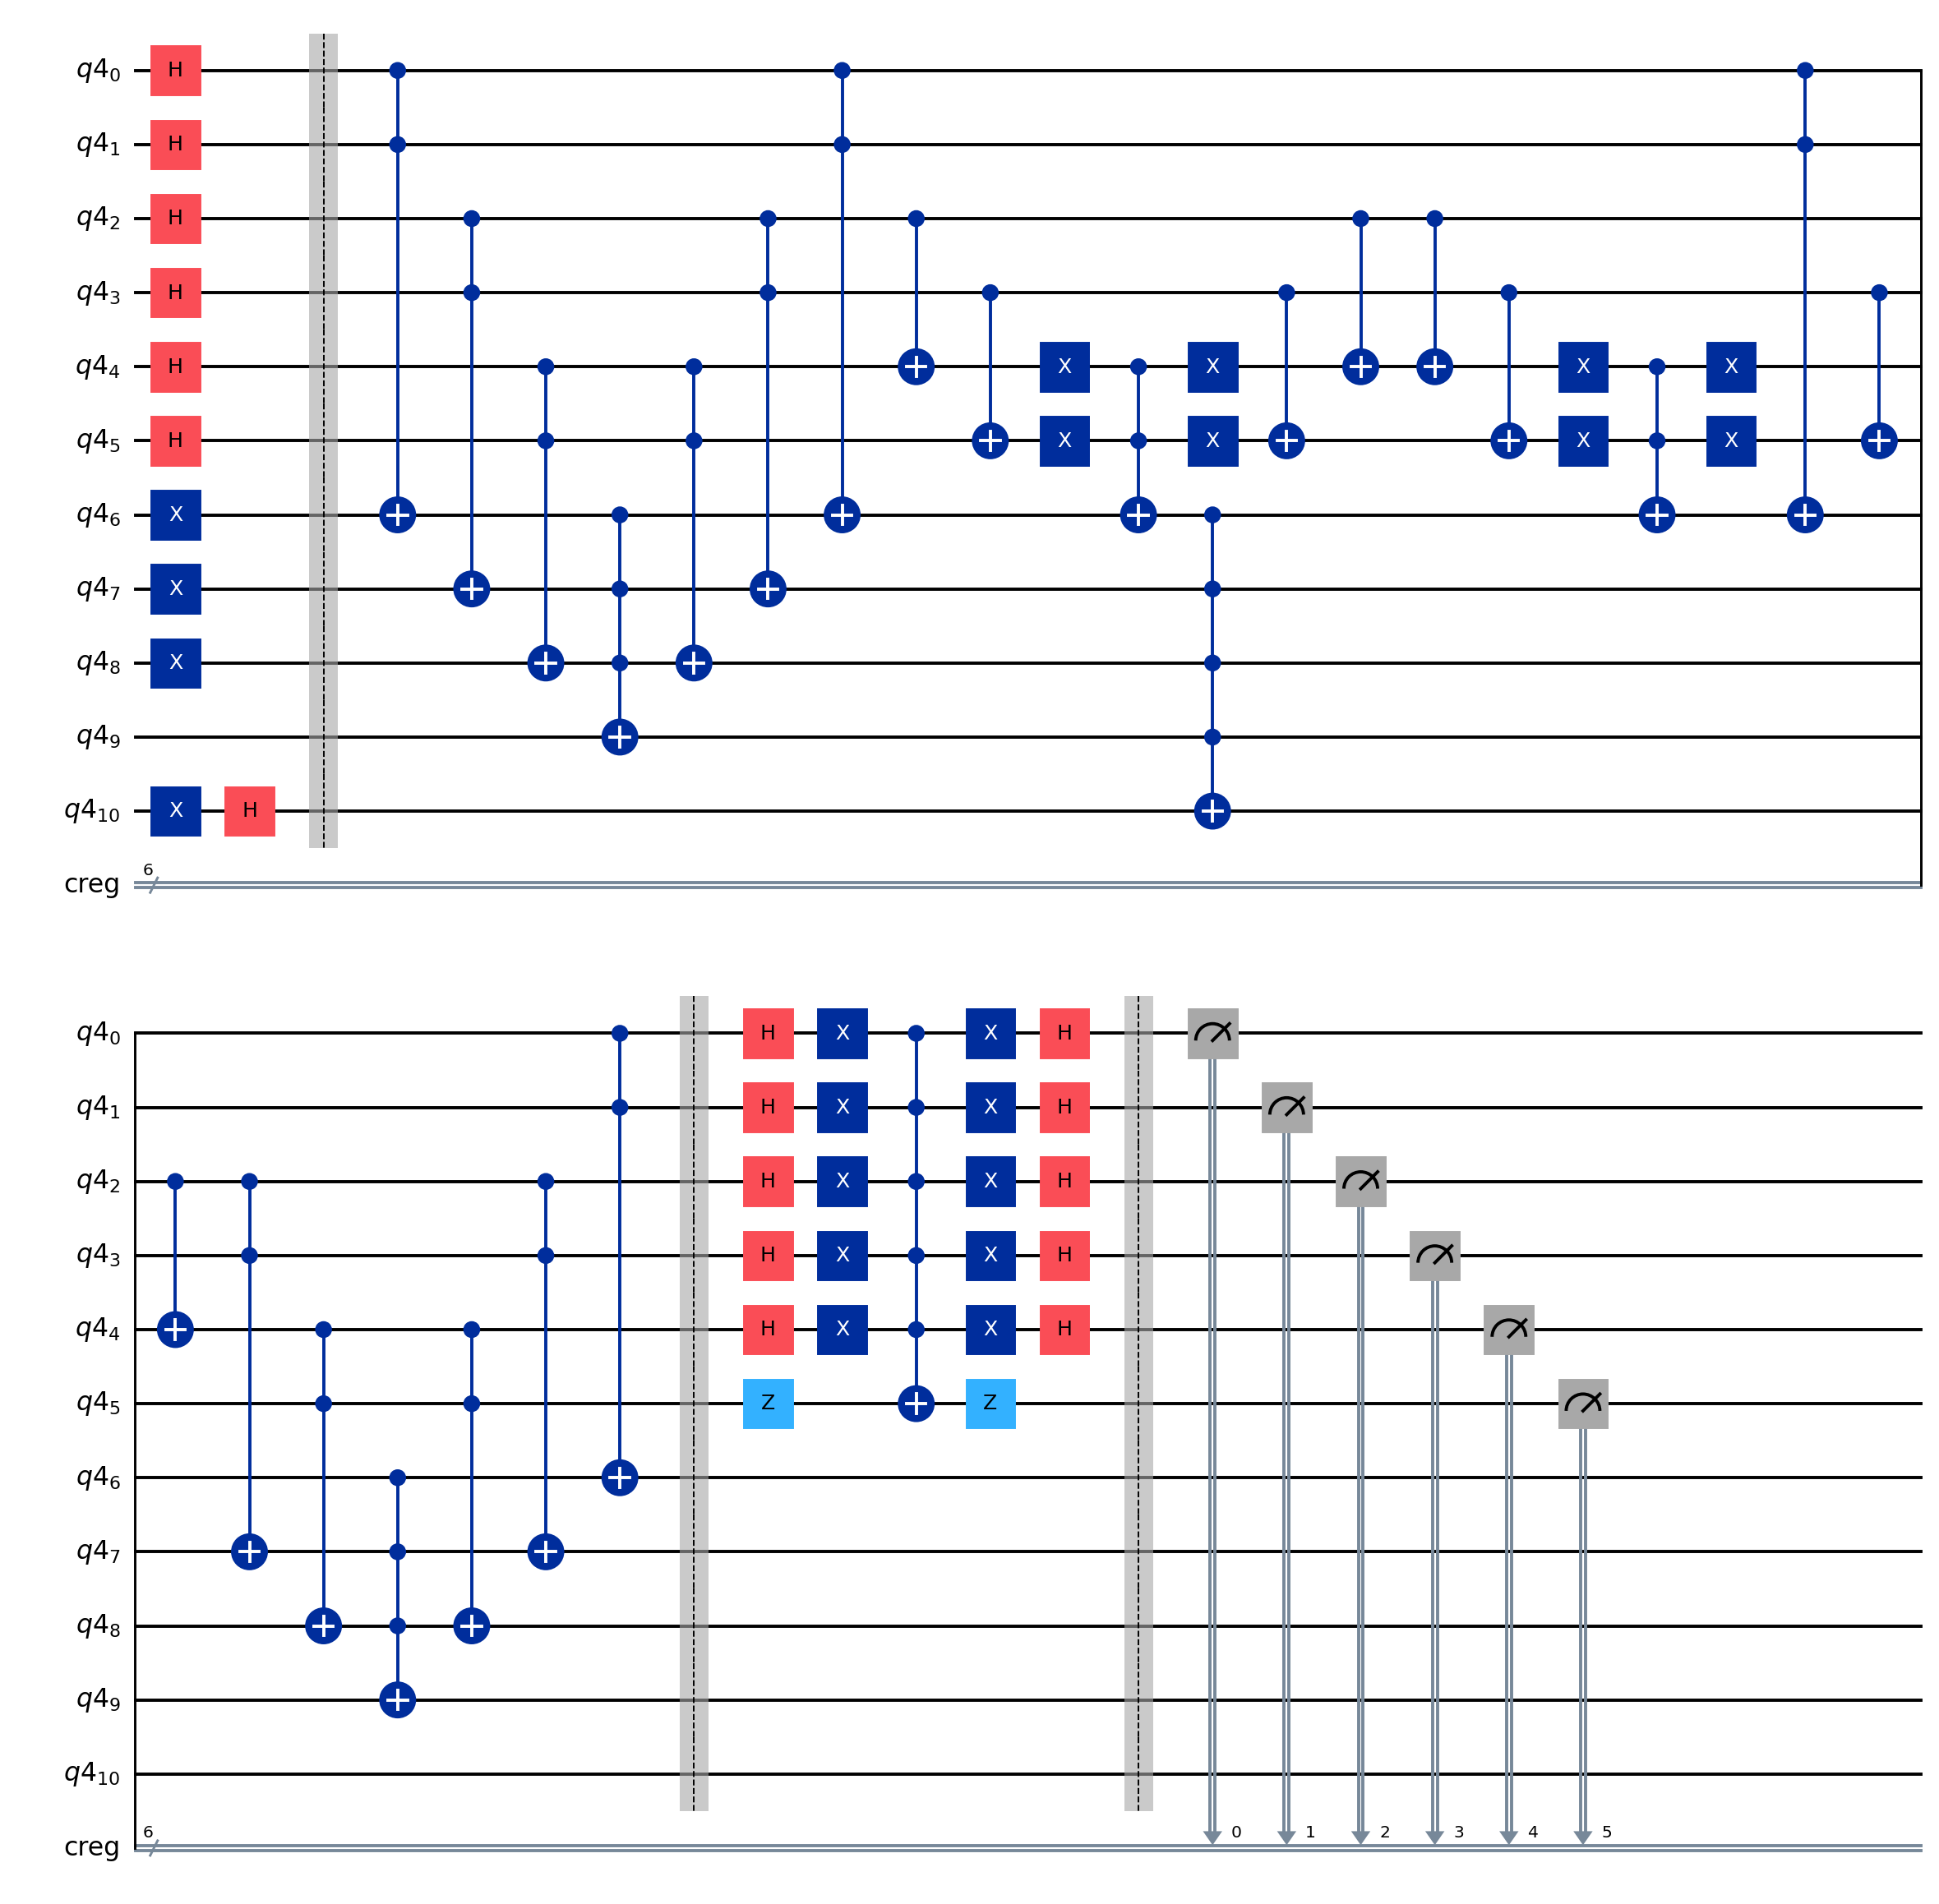

In [94]:
for variant in variants:
    method = f"sb_{variant}"
    figure = circuits[method].draw("mpl", fold=24, idle_wires=False)
    figure.savefig(FIGURES / f"{method}-circuit.svg", bbox_inches="tight")
    if variant == "original":
        show_figure(figure, f"{method}-circuit")
    else:
        plt.close(figure)

## 8. Count exactly what the paper counts

The small helper below defines all three historical metrics locally.

| Reported metric | Historical definition |
|---|---|
| Width | Allocated circuit qubits plus $\sum\max(0,n-2)$ over `mcx` instructions except the last, where $n$ counts controls. The last is assumed to be diffusion. This allowance is not allocated workspace. |
| Depth | `circuit.depth(mcx_decomposition=True)`: the local patch weights an $n$-controlled X by $\lceil\log_2 n\rceil$ for $n\ge2$. This is an analytical estimate, not a synthesized hardware or T-depth. |
| Gates | `len(circuit)`, including barriers and measurements. |

The historical table leaves Logique unmeasured while measuring all baselines.
For the second table, add one final barrier and six data measurements to a
**copy** of Logique. The other methods already have these measurements.

In [95]:
import inspect

assert (
    "mcx_decomposition" in inspect.signature(QuantumCircuit.depth).parameters
), "Install tools/patch_qiskit_depth.py, then restart the kernel."


def paper_metrics(circuit: QuantumCircuit) -> dict[str, int]:
    """Count resources using the paper's historical accounting rules."""
    mcx = [gate.operation for gate in circuit.data if gate.operation.name == "mcx"]
    # The final MCX belongs to diffusion and receives no extra width allowance.
    allowance = sum(max(0, gate.num_ctrl_qubits - 2) for gate in mcx[:-1])
    return {
        "width": circuit.num_qubits + allowance,
        "depth": circuit.depth(mcx_decomposition=True),
        "gates": len(circuit),
    }

### Make measurement accounting explicit

Copy the Logique circuit and add the final barrier and six data measurements.
The original circuit stays unmeasured for the historical table.

In [96]:
from qiskit import ClassicalRegister

measured_vcgc = vcgc.copy()
measured_vcgc.add_register(ClassicalRegister(input_count, "creg"))
measured_vcgc.barrier()
measured_vcgc.measure(range(input_count), range(input_count))
measured_circuits = {**circuits, "vcgc": measured_vcgc}

### Compare the five methods

Compute the same three metrics for every circuit. Show the original paper
accounting first, then the table with all methods measured.

In [97]:
from IPython.display import Markdown

historical_costs = {method: paper_metrics(circuits[method]) for method in methods}
measured_costs = {
    method: paper_metrics(measured_circuits[method]) for method in methods
}
historical_table = pd.DataFrame.from_dict(historical_costs, orient="index")
measured_table = pd.DataFrame.from_dict(measured_costs, orient="index")
display(Markdown("**Historical accounting**"))
display(historical_table)
display(Markdown("**All methods measured**"))
display(measured_table)

**Historical accounting**

,width,depth,gates
vcgc,11,30,73
sb_original,15,28,76
sb_minimal,13,90,211
sb_simple,17,40,107
sb_balanced,15,64,147


**All methods measured**

,width,depth,gates
vcgc,11,31,80
sb_original,15,28,76
sb_minimal,13,90,211
sb_simple,17,40,107
sb_balanced,15,64,147


Measuring Logique should add seven instructions and one layer of depth,
without changing width. The four baselines already contain measurements.
The checks below make that difference explicit.

In [98]:
display(measured_table - historical_table)


assert measured_costs["vcgc"]["gates"] == historical_costs["vcgc"]["gates"] + 7
assert measured_costs["vcgc"]["depth"] == historical_costs["vcgc"]["depth"] + 1
assert measured_costs["vcgc"]["width"] == historical_costs["vcgc"]["width"]
for method in methods[1:]:
    assert measured_costs[method] == historical_costs[method]

,width,depth,gates
vcgc,0,1,7
sb_original,0,0,0
sb_minimal,0,0,0
sb_simple,0,0,0
sb_balanced,0,0,0


### Understand the reported width and depth

The paper's width includes an MCX allowance beyond the allocated wires. Its
weighted depth also differs from ordinary Qiskit depth. Compare both here.

In [99]:
display(
    pd.DataFrame(
        [
            {
                "method": method,
                "allocated qubits": circuits[method].num_qubits,
                "MCX allowance": historical_costs[method]["width"]
                - circuits[method].num_qubits,
                "historical width": historical_costs[method]["width"],
                "ordinary Qiskit depth": circuits[method].depth(),
                "weighted depth estimate": historical_costs[method]["depth"],
            }
            for method in methods
        ]
    )
)

,method,allocated qubits,MCX allowance,historical width,ordinary Qiskit depth,weighted depth estimate
0,vcgc,11,0,11,28,30
1,sb_original,11,4,15,24,28
2,sb_minimal,11,2,13,88,90
3,sb_simple,13,4,17,38,40
4,sb_balanced,11,4,15,61,64


## 9. Compare with the archived paper row

The archived row supplies the expected values. Compare all 15 metrics with
our freshly constructed circuits and save any differences in `comparison.csv`.

In [100]:
reference_path = (
    ROOT / "experiments/manuscript/legacy/data/output/benchmark_results.csv"
)
archived = pd.read_csv(reference_path).set_index("benchmark").loc[BENCHMARK]
comparison = pd.DataFrame(
    [
        {
            "benchmark": BENCHMARK,
            "metric": f"{method}_{metric}",
            "old": int(archived[f"{method}_{metric}"]),
            "new": historical_costs[method][metric],
        }
        for method in methods
        for metric in ("width", "depth", "gates")
    ]
)

In [101]:
comparison["delta"] = comparison["new"] - comparison["old"]
comparison["exact"] = comparison["delta"] == 0
comparison.to_csv(OUT / "comparison.csv", index=False)
display(comparison)
assert comparison[
    "exact"
].all(), "Historical mismatch: inspect comparison.csv and dependency versions."
print(f"{int(comparison['exact'].sum())}/15 historical metrics match.")

,benchmark,metric,old,new,delta,exact
0,K3,vcgc_width,11,11,0,True
1,K3,vcgc_depth,30,30,0,True
2,K3,vcgc_gates,73,73,0,True
3,K3,sb_original_width,15,15,0,True
4,K3,sb_original_depth,28,28,0,True
5,K3,sb_original_gates,76,76,0,True
6,K3,sb_minimal_width,13,13,0,True
7,K3,sb_minimal_depth,90,90,0,True
8,K3,sb_minimal_gates,211,211,0,True
9,K3,sb_simple_width,17,17,0,True


15/15 historical metrics match.


## 10. Plot the costs

Save the two tables in the paper's CSV format, then use the shared
`plot_results()` function to draw width, depth, and instruction counts.
The loader maps the paper's `vcgc` name to `logique` and `width` to `qubits`.

The plots compare resource costs under the replay choices above. Coloring
success probabilities are a separate question.

In [102]:
# Write the wide CSV format used by the paper's plotting tools.
graph_info = {
    "benchmark": BENCHMARK,
    "nodes": len(problem.vertices),
    "edges": len(problem.edges),
    "colors": problem.colors,
}
for costs, filename in (
    (historical_costs, "benchmark_results.csv"),
    (measured_costs, "measurement_consistent_results.csv"),
):
    row = dict(graph_info)
    for method in methods:
        for metric, value in costs[method].items():
            row[f"{method}_{metric}"] = value
    pd.DataFrame([row]).to_csv(OUT / filename, index=False)

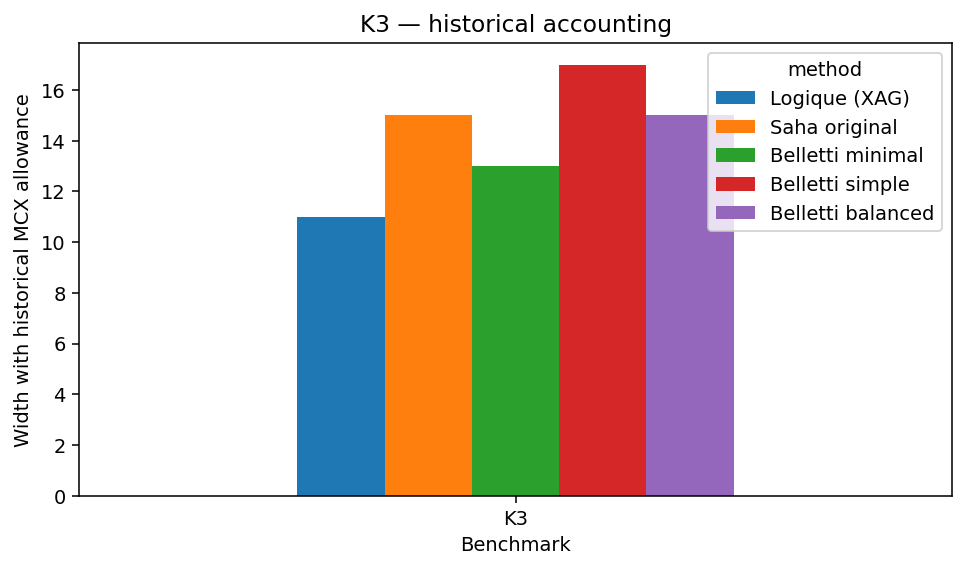

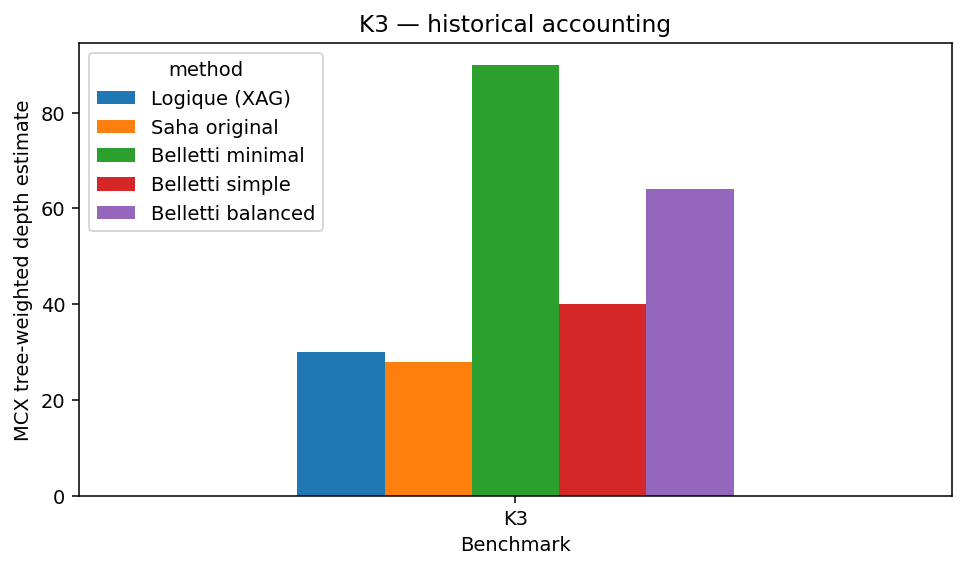

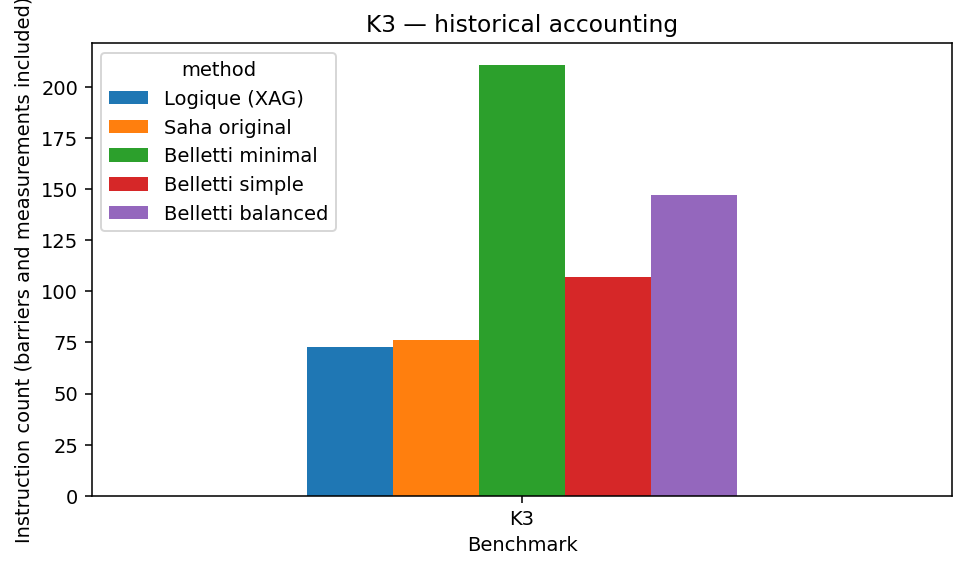

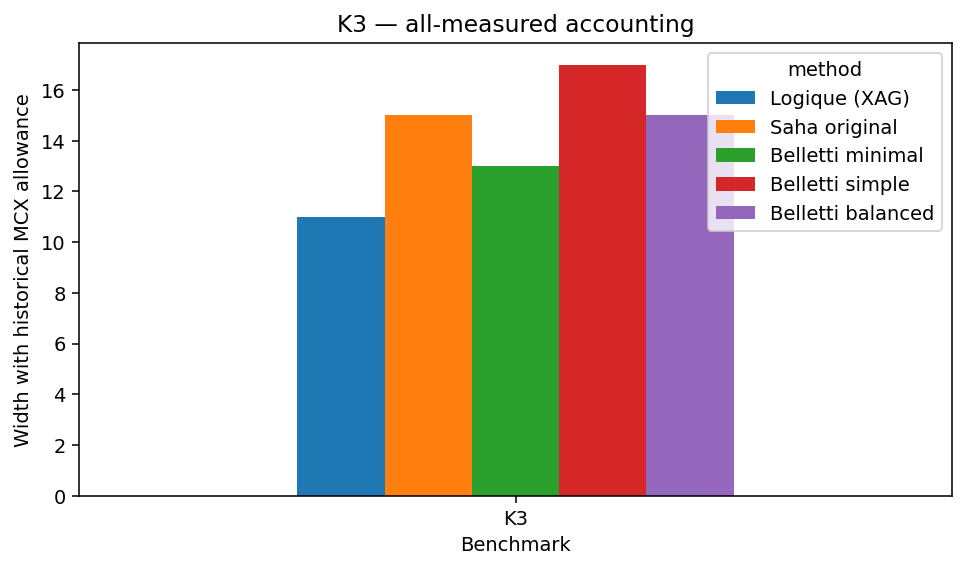

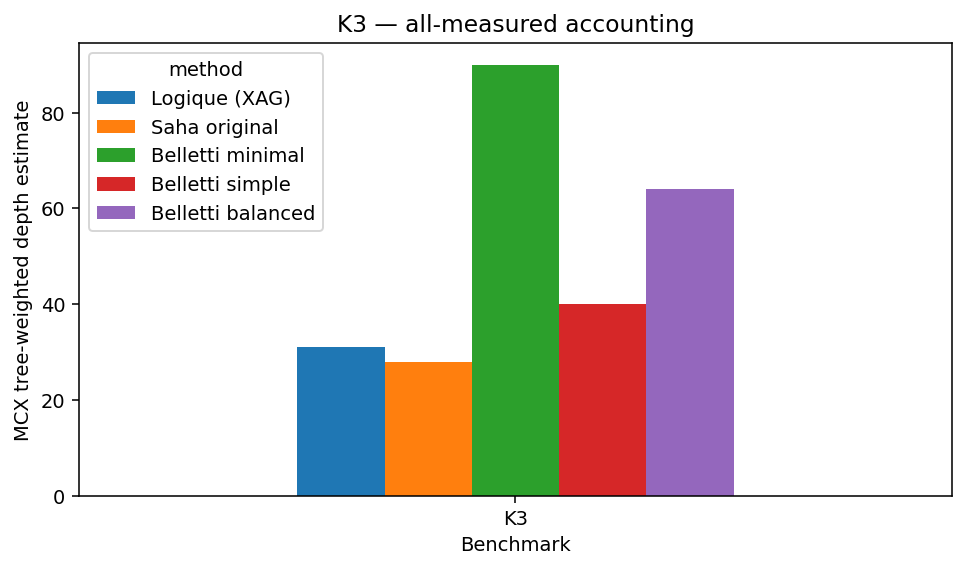

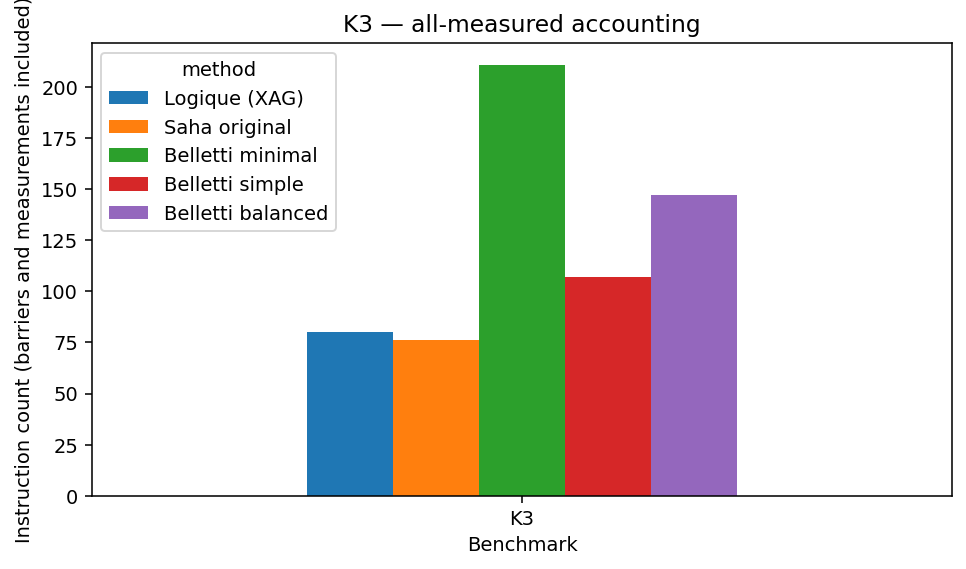

In [103]:
from logique.visualization.results import plot_results

method_labels = {
    "logique": "Logique (XAG)",
    "sb_original": "Saha original",
    "sb_minimal": "Belletti minimal",
    "sb_simple": "Belletti simple",
    "sb_balanced": "Belletti balanced",
}
for accounting, filename in (
    ("historical", "benchmark_results.csv"),
    ("all-measured", "measurement_consistent_results.csv"),
):
    for metric, ylabel in (
        ("qubits", "Width with historical MCX allowance"),
        ("depth", "MCX tree-weighted depth estimate"),
        ("gates", "Instruction count (barriers and measurements included)"),
    ):
        figure = plot_results(
            OUT / filename, metric=metric, method_labels=method_labels
        )
        ax = figure.axes[0]
        ax.set_ylabel(ylabel)
        ax.set_title(f"K3 — {accounting} accounting")
        ax.tick_params(axis="x", labelrotation=0)
        show_figure(figure, f"{accounting}-{metric}")

## 11. Save circuits and provenance

The benchmark results are complete. The remaining cells save the six QASM
circuits and record the package versions, checkout, replay choices, and
verification in `benchmark_manifest.json`. The notebook runner keeps its own
execution record in `run.json`.

In [104]:
from qiskit.qasm3 import dump

for method, circuit in circuits.items():
    with (OUT / f"{BENCHMARK}_{method}.qasm").open("w") as stream:
        dump(circuit, stream)
with (OUT / f"{BENCHMARK}_vcgc_measured.qasm").open("w") as stream:
    dump(measured_vcgc, stream)

Record the choices that someone needs to reproduce this run. Keeping this
metadata beside the exported circuits makes their accounting clear later.

In [105]:
from logique.benchmarks.provenance import checkout_revision, environment

manifest = {
    "benchmark": BENCHMARK,
    "input": str(input_path.relative_to(ROOT)),
    "versions": environment(),
    "checkout": checkout_revision(ROOT),
    "iterations": 1,
    "depth_model": "logique.mcx_tree_bound.v1",
    "precolors": "ignored; removed " + str(dict(original.precolored)),
    "encoding": "edge inequalities only; expression-tree frontend",
    "preparation": "Logique: valid colors; baselines: Hadamards",
    "oracle": "single XAG application with output in |minus>; internal cleanup",
    "baseline_labels": "original one-based labels, without normalization",
    "measurements": {
        "benchmark_results.csv": "Logique unmeasured; baselines measured",
        "measurement_consistent_results.csv": "all five methods measured",
    },
    "verification": verification,
    "historical_metrics_match": bool(comparison["exact"].all()),
}
(OUT / "benchmark_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")

1910

## 12. Further inspection: draw the expression XAG

This section draws the expression-built XAG used by the historical synthesis
path, with the same vertex/bit labels as the earlier diagrams. AND/XOR gate
labels and dashed inversion edges make the logic easier to follow.

The drawing code is more detailed because tweedledum's DOT writer uses numeric
input labels. Recreate the network from the same expression and variable order,
then change only the displayed labels. The quantum circuit is unchanged.

The earlier native reference networks may be refactored. This view preserves
the expression frontend's logic structure; it does not show quantum workspace
or uncomputation. Save its DOT and SVG files alongside the other figures.

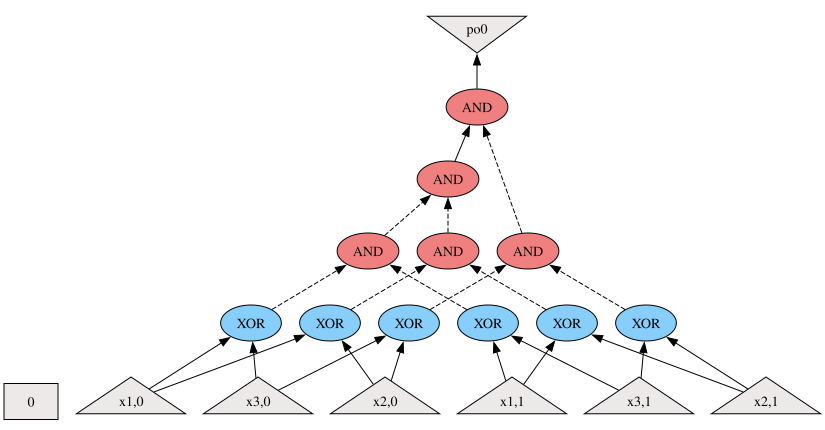

Expression XAG: 6 inputs, 1 outputs, 11 gates
DOT: /Users/mac/PhD/logique/dump/1018203055-illustrative-example-v2/figures/expression-xag.dot
SVG: /Users/mac/PhD/logique/dump/1018203055-illustrative-example-v2/figures/expression-xag.svg


In [106]:
from graphviz import Digraph, Source
from tweedledum.bool_function_compiler.bool_function import BoolFunction
from tweedledum.classical import write_gate_dot

expression_function = BoolFunction.from_expression(expression, variables)
expression_xag = expression_function.logic_network()
xag_dot_path = FIGURES / "expression-xag.dot"
xag_svg_path = FIGURES / "expression-xag.svg"
write_gate_dot(expression_xag, str(xag_dot_path))
# Override primary-input labels without changing node IDs or edges.
input_label_overrides = Digraph()
for wire, label in enumerate(input_labels):
    node = expression_xag.pi_at(wire)
    subscript = label.split("_", 1)[1]
    input_label_overrides.node(str(node), label=f"<x{subscript}>")
raw_dot = xag_dot_path.read_text()
dot_end = raw_dot.rindex("}")
labeled_dot = (
    raw_dot[:dot_end] + "".join(input_label_overrides.body) + raw_dot[dot_end:]
)
xag_dot_path.write_text(labeled_dot)
xag_svg = Source(labeled_dot).pipe(format="svg")
xag_svg_path.write_bytes(xag_svg)
display(SVG(data=xag_svg))
print(
    "Expression XAG:",
    expression_xag.num_pis(),
    "inputs,",
    expression_xag.num_pos(),
    "outputs,",
    expression_xag.num_gates(),
    "gates",
)
print("DOT:", xag_dot_path)
print("SVG:", xag_svg_path)

## 13. Find the saved artifacts

The run folder contains the cost tables, circuits, figures, and provenance.
The links below open the main files. Source notebook outputs stay empty;
the notebook runner saves an executed copy under `dump/`.

In [107]:
display(
    pd.Series(
        {
            "depth model": manifest["depth_model"],
            "precolors": manifest["precolors"],
            "encoding": manifest["encoding"],
            "preparation": manifest["preparation"],
            "oracle": manifest["oracle"],
            "baseline labels": manifest["baseline_labels"],
        },
        name="replay conventions",
    ).to_frame()
)
display(pd.Series(manifest["versions"], name="version").to_frame())

,replay conventions
depth model,logique.mcx_tree_bound.v1
precolors,ignored; removed {1: 0}
encoding,edge inequalities only; expression-tree frontend
preparation,Logique: valid colors; baselines: Hadamards
oracle,single XAG application with output in |minus>;...
baseline labels,"original one-based labels, without normalization"


,version
python,3.10.18
caterpillar,4c6f766cd0ffc62d37ab45edfe80c9f1eae44764
bridge_fixes,"lhrs_uncompute_stack_pop, best_fit_cell_fanout"
logique,0.2.0
qiskit,2.1.1
tweedledum,1.1.1
numpy,2.2.6
saha-belleti,0.1.0
qiskit-ibm-runtime,0.41.1


In [108]:
link_base = OUT if "LOGIQUE_OUTPUT" in os.environ else ROOT / "experiments/tutorials"
for label, path in (
    ("Benchmark provenance", OUT / "benchmark_manifest.json"),
    ("Historical metrics", OUT / "benchmark_results.csv"),
    ("All-measured metrics", OUT / "measurement_consistent_results.csv"),
    ("Archived-versus-current comparison", OUT / "comparison.csv"),
    ("Logique Grover circuit", OUT / "K3_vcgc.qasm"),
    ("Measured Logique circuit", OUT / "K3_vcgc_measured.qasm"),
    ("Expression XAG DOT source", FIGURES / "expression-xag.dot"),
    ("Expression XAG diagram", FIGURES / "expression-xag.svg"),
    ("Digital logic schematic", FIGURES / "edge-predicate-schematic.svg"),
    ("Full Grover diagram", FIGURES / "one-grover-iteration.svg"),
):
    assert path.is_file()
    relative_link = os.path.relpath(path, link_base)
    display(Markdown(f"[{label}]({relative_link})"))

[Benchmark provenance](../../dump/1018203055-illustrative-example-v2/benchmark_manifest.json)

[Historical metrics](../../dump/1018203055-illustrative-example-v2/benchmark_results.csv)

[All-measured metrics](../../dump/1018203055-illustrative-example-v2/measurement_consistent_results.csv)

[Archived-versus-current comparison](../../dump/1018203055-illustrative-example-v2/comparison.csv)

[Logique Grover circuit](../../dump/1018203055-illustrative-example-v2/K3_vcgc.qasm)

[Measured Logique circuit](../../dump/1018203055-illustrative-example-v2/K3_vcgc_measured.qasm)

[Expression XAG DOT source](../../dump/1018203055-illustrative-example-v2/figures/expression-xag.dot)

[Expression XAG diagram](../../dump/1018203055-illustrative-example-v2/figures/expression-xag.svg)

[Digital logic schematic](../../dump/1018203055-illustrative-example-v2/figures/edge-predicate-schematic.svg)

[Full Grover diagram](../../dump/1018203055-illustrative-example-v2/figures/one-grover-iteration.svg)

In [109]:
print("All files:")
for path in sorted(OUT.rglob("*")):
    if path.is_file():
        print(path.relative_to(OUT))

All files:
K3_expression.v
K3_sb_balanced.qasm
K3_sb_minimal.qasm
K3_sb_original.qasm
K3_sb_simple.qasm
K3_vcgc.qasm
K3_vcgc_measured.qasm
benchmark_manifest.json
benchmark_results.csv
comparison.csv
figures/all-measured-depth.png
figures/all-measured-depth.svg
figures/all-measured-gates.png
figures/all-measured-gates.svg
figures/all-measured-qubits.png
figures/all-measured-qubits.svg
figures/edge-predicate-schematic.png
figures/edge-predicate-schematic.svg
figures/expression-xag.dot
figures/expression-xag.svg
figures/historical-depth.png
figures/historical-depth.svg
figures/historical-gates.png
figures/historical-gates.svg
figures/historical-qubits.png
figures/historical-qubits.svg
figures/mapped-reference-network.dot
figures/mapped-reference-network.svg
figures/one-grover-iteration.png
figures/one-grover-iteration.svg
figures/paper-graph.png
figures/paper-graph.svg
figures/probability-groups.png
figures/probability-groups.svg
figures/raw-circuit-excerpt.png
figures/raw-circuit-excerp

To reproduce the walkthrough from the repository root:

```bash
uv run --no-sync logique notebook run experiments/tutorials/paper_benchmark_walkthrough.ipynb --offline
```

Questions to explore after this replay: Which costs come from state preparation,
oracle computation, diffusion, and measurement? How does enforcing the full
three-color predicate change the oracle? How does reflecting about the initial
state change the probabilities? Use the separate full-predicate tutorial for
those changes; changing these choices would define a different benchmark from
the archived paper row.